# Xiaohongshu — DSE vs IELTS AI track analysis

Pipeline: **search** (`crawler.xhs_crawler`) → **enrich** (`crawler.xhs_enrich`, full body + comments) → **NLP** (`python -m src.nlp.process`).

Processed `text_full` = title + body (`body_full` or `desc`) + concatenated public comments for that note. Run `python -m src.nlp.process` from project root to refresh `data/processed/metrics.json` and processed CSVs.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path('..').resolve()
PROC = ROOT / 'data' / 'processed'
VIZ = ROOT / 'Visualization'
VIZ.mkdir(exist_ok=True)

In [2]:
metrics = json.loads((PROC / 'metrics.json').read_text(encoding='utf-8'))
metrics.keys()

dict_keys(['dse', 'ielts_ai'])

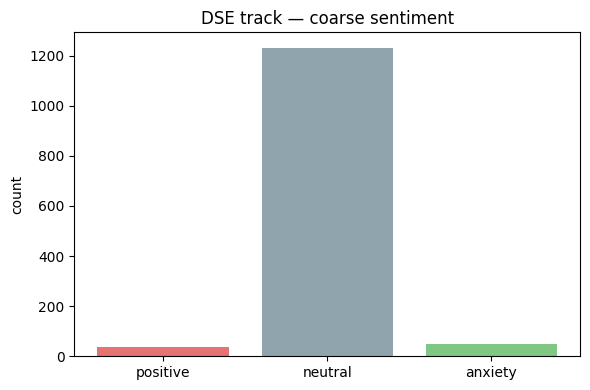

Saved E:\Project4\jd_drissionpage_new\Visualization\sentiment_dse.png


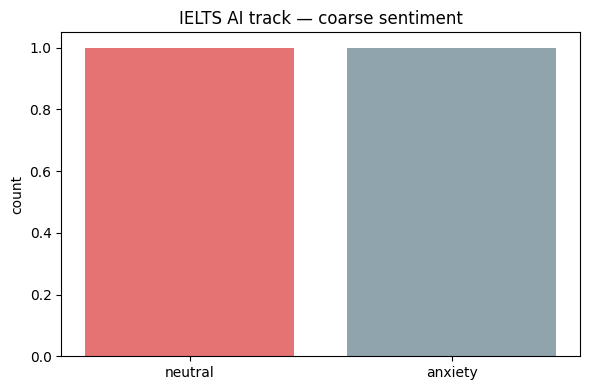

Saved E:\Project4\jd_drissionpage_new\Visualization\sentiment_ielts_ai.png


In [3]:
def plot_sentiment(track: str, title: str):
    m = metrics.get(track, {})
    sd = m.get('sentiment_distribution', {})
    if not sd:
        print('No data for', track)
        return
    labels = list(sd.keys())
    vals = [sd[k] for k in labels]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, vals, color=['#e57373', '#90a4ae', '#81c784'])
    ax.set_title(title)
    ax.set_ylabel('count')
    plt.tight_layout()
    out = VIZ / f'sentiment_{track}.png'
    fig.savefig(out, dpi=120)
    plt.show()
    print('Saved', out)

plot_sentiment('dse', 'DSE track — coarse sentiment')
plot_sentiment('ielts_ai', 'IELTS AI track — coarse sentiment')

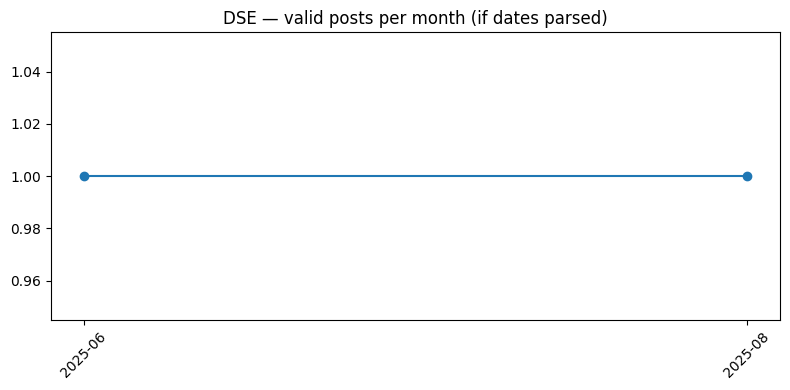

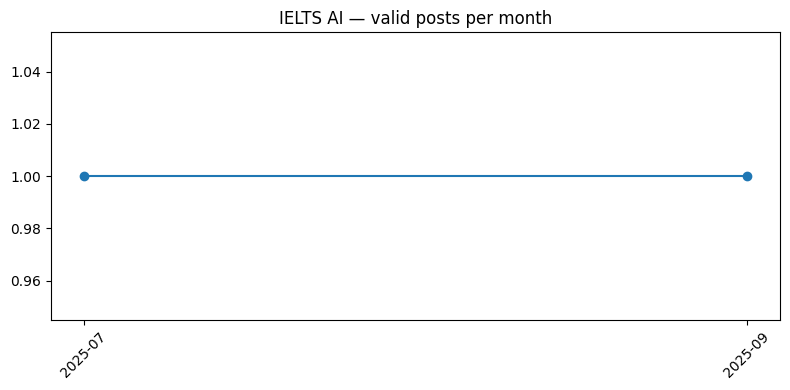

In [4]:
def plot_monthly(track: str, title: str):
    m = metrics.get(track, {})
    mc = m.get('monthly_counts') or {}
    if not mc:
        print('No monthly data for', track)
        return
    keys = sorted(mc.keys())
    vals = [mc[k] for k in keys]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(keys, vals, marker='o')
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    out = VIZ / f'monthly_{track}.png'
    fig.savefig(out, dpi=120)
    plt.show()

plot_monthly('dse', 'DSE — valid posts per month (if dates parsed)')
plot_monthly('ielts_ai', 'IELTS AI — valid posts per month')

In [5]:
for track, label in [('dse', 'DSE'), ('ielts_ai', 'IELTS_AI')]:
    p = PROC / f'xhs_{track}_processed.csv'
    if not p.exists():
        continue
    df = pd.read_csv(p, encoding='utf-8-sig')
    print(label, 'valid rows', len(df))

DSE valid rows 1317
IELTS_AI valid rows 2


In [6]:
# Optional: copy word clouds into Visualization/ for the course pack
from shutil import copyfile
for t in ("dse", "ielts_ai"):
    src = ROOT / "app" / "static" / "figures" / f"wordcloud_{t}.png"
    if src.exists():
        copyfile(src, VIZ / f"wordcloud_{t}.png")
        print("Copied", src.name)

Copied wordcloud_dse.png
Copied wordcloud_ielts_ai.png
